# **Idade e trajetória dos participantes**

**Área de análise:** Pará (PA)  
**Referência territorial:** município da escola (ESC)  
**Período:** 1998–2023 para participação; 2001–2023 para desempenho.\
**Fonte:** `faixa`,`dsp`

**OBJETIVO**

Investigar a composição etária dos participantes do ENEM no Pará, sua evolução ao longo do tempo e as diferenças de desempenho entre as faixas etárias (<17, 17–20, 21–25, 26–40 e >40 anos).

<div style="background-color: #f5f0dc; padding: 12px; border-radius: 6px;">
    
> **Nota Metodológica**  
> Os resultados de 2001–2008 aparecem em magnitudes distintas dos resultados a partir de 2009. Em 2001, por exemplo, as médias da prova objetiva estão na faixa de dezenas, enquanto em 2009 as áreas do conhecimento aparecem na faixa de centenas. Assim, não se deve interpretar a passagem de 2008 para 2009 como uma variação direta de desempenho. As comparações históricas devem respeitar a mudança de estrutura e escala do exame. A partir de 2009, a análise considera CH, CN, LC, MT e Redação.

 </div>
 
## Principais achados
<div style="background-color: #DBEAFE; padding: 12px; border-radius: 6px;">

> **Concentração crescente nas faixas mais jovens**  
> A participação da faixa de **17–20 anos** passou de **54,6% em 2001 para 92,2% em 2023**. Considerando todos os participantes com até 20 anos, a proporção aumentou de **56,1% para 93,6%**.

> **Diferenças expressivas de desempenho entre os extremos etários**  
> Em 2023, a diferença entre as médias dos participantes com menos de 17 anos e daqueles acima de 40 anos chegou a **402,2 pontos em Redação** e **176,7 pontos em Matemática**.

> **Cobertura territorial desigual entre as faixas etárias**  
> Em 2023, a faixa de 17–20 anos apresentou registros em **141 municípios**, enquanto a faixa acima de 40 anos esteve representada em **34 municípios**, o que limita a comparabilidade territorial entre os grupos.
 </div>

## Configuração e carga

In [1]:
from _setup2 import *

UF_PROCESSAMENTO = "PA"
TIPO_REFERENCIA = "ESC"

out = read_allfiles2(UF_PROCESSAMENTO, TIPO_REFERENCIA)

faixa = out["faixa"]["data"].copy()
dsp = out["dsp"]["data"].copy()

COLUNA_FAIXA_PARTICIPACAO = None
COLUNA_CONTAGEM_FAIXA = None
participacao_idade = eda2.preparar_participacao_idade(faixa,coluna_contagem=COLUNA_CONTAGEM_FAIXA,coluna_faixa=COLUNA_FAIXA_PARTICIPACAO,)
desempenho_idade = eda2.preparar_desempenho_idade_dsp(dsp, referencia=TIPO_REFERENCIA)

print("=" * 46)
print(f"UF: {UF_PROCESSAMENTO}  | Período :{faixa['ano'].min()}–{faixa['ano'].max()}| Referência: {TIPO_REFERENCIA} ")
print("=" * 46)
print(f"faixa   : {faixa.shape[0]:,} x {faixa.shape[1]}".replace(",", "."))
print(f"dsp     : {dsp.shape[0]:,} x {dsp.shape[1]}".replace(",", "."))
print("=" * 46)


UF: PA  | Período :1998–2023| Referência: ESC 
faixa   : 38.335 x 7
dsp     : 250.436 x 17


## 1. Evolução da distribuição etária

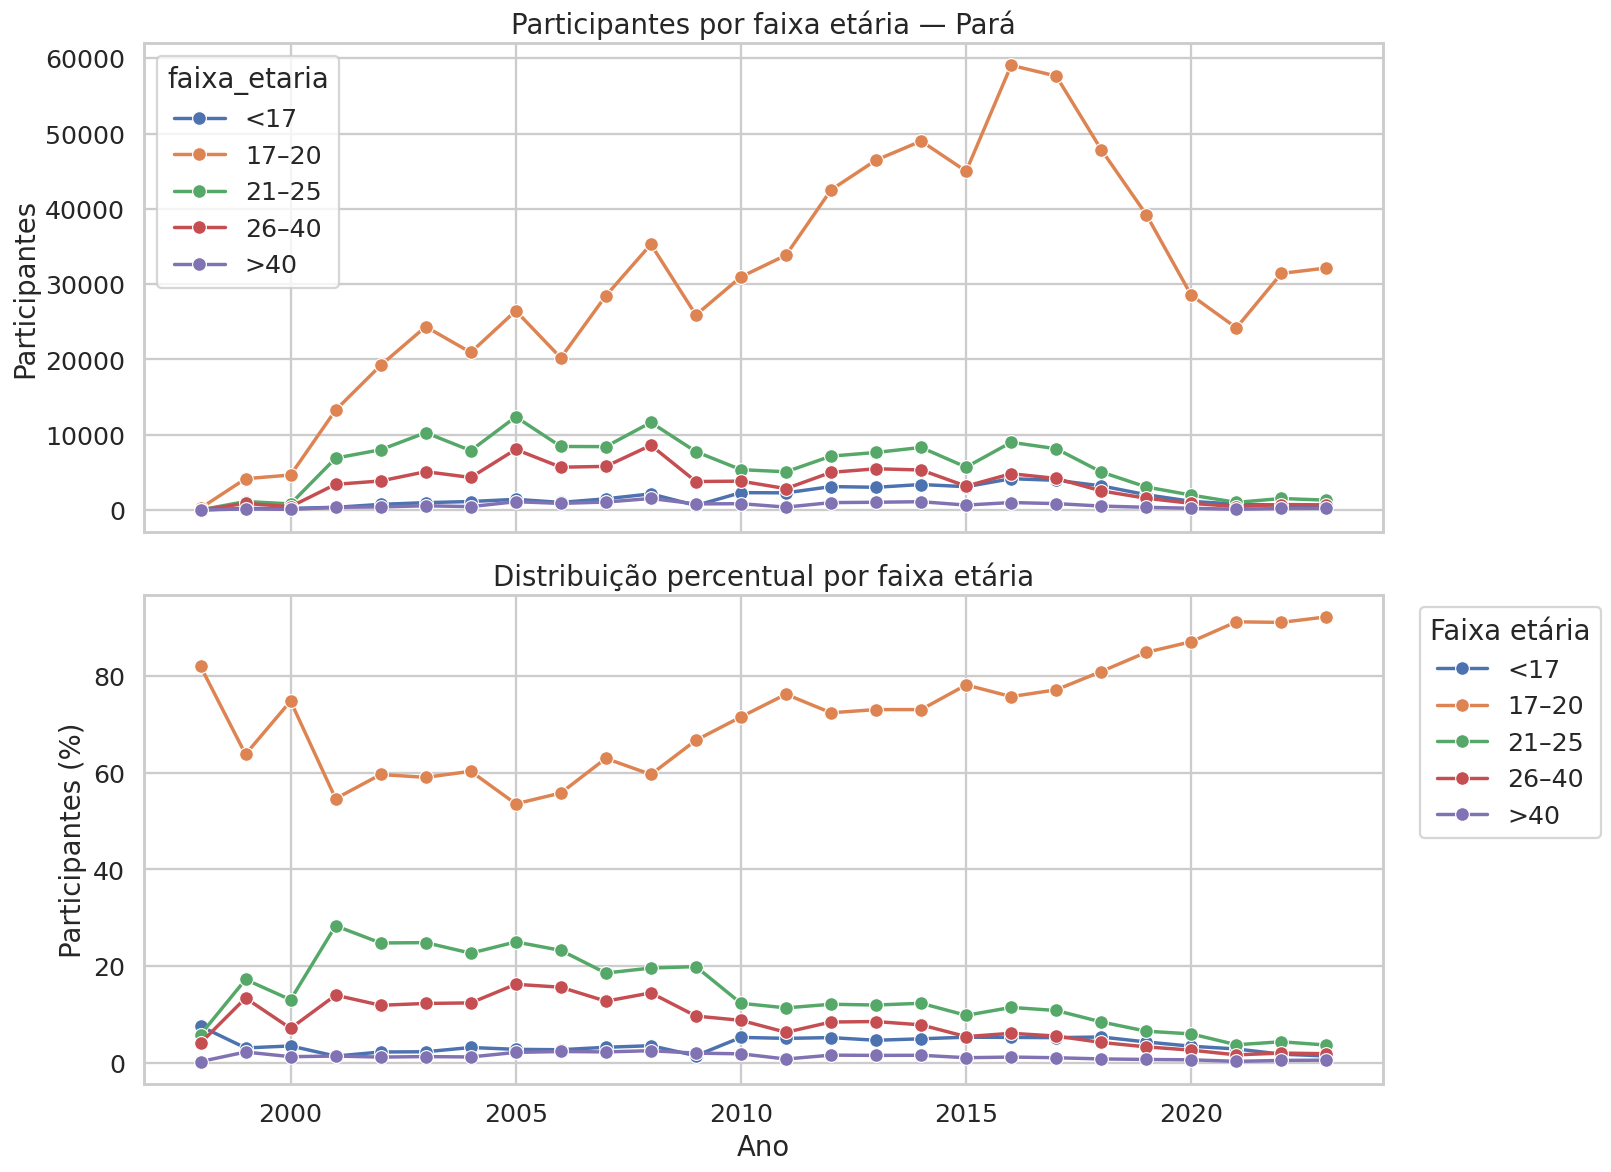

In [2]:
distribuicao_idade = eda2.calcular_distribuicao_idade(participacao_idade)


fig, axes = plt.subplots(2, 1, figsize=(15, 11), sharex=True)
sns.lineplot(
    data=distribuicao_idade, x="ano", y="participantes",
    hue="faixa_etaria", marker="o", ax=axes[0]
)
axes[0].set(title="Participantes por faixa etária — Pará",
            xlabel="", ylabel="Participantes")
sns.lineplot(
    data=distribuicao_idade, x="ano", y="percentual",
    hue="faixa_etaria", marker="o", ax=axes[1]
)
axes[1].set(title="Distribuição percentual por faixa etária",
            xlabel="Ano", ylabel="Participantes (%)")
axes[1].legend(title="Faixa etária", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()



### Comentários
A distribuição etária mostra predominância da faixa de 17–20 anos durante todo o período analisado. Entretanto, sua participação relativa aumentou de forma expressiva ao longo da série, sobretudo a partir de 2009.

Em 2001, a faixa de 17–20 anos representava aproximadamente 54,6% dos participantes. A faixa de 21–25 anos correspondia a 28,4%, enquanto a de 26–40 anos representava 14,0%.

Em 2008, a participação de 17–20 anos havia aumentado para 59,6%. A partir de 2009, essa concentração se intensificou: chegou a 73,0% em 2014, 84,8% em 2019 e 92,2% em 2023.

| Ano  | <17  | 17–20 | 21–25 | 26–40 | >40  |
| ---- | ----:| -----:| -----:| -----:| ----:|
| 2001 | 1,5% | 54,6% | 28,4% | 14,0% | 1,5% |
| 2008 | 3,6% | 59,6% | 19,7% | 14,5% | 2,6% |
| 2009 | 1,6% | 66,7% | 19,9% | 9,7%  | 2,1% |
| 2014 | 5,0% | 73,0% | 12,4% | 7,9%  | 1,6% |
| 2019 | 4,4% | 84,8% | 6,6%  | 3,4%  | 0,8% |
| 2021 | 2,9% | 91,1% | 3,8%  | 1,7%  | 0,4% |
| 2023 | 1,5% | 92,2% | 3,8%  | 2,0%  | 0,6% |

A composição etária dos inscritos tornou-se progressivamente mais concentrada na faixa de 17–20 anos. Em paralelo, as faixas acima de 20 anos perderam participação relativa. O movimento é particularmente acentuado depois de 2014.

A faixa <17 permanece minoritária e apresenta oscilações. Já a faixa >40 representa uma parcela pequena em toda a série.
Os dados de participação disponíveis terminam em 2023. Portanto, não é possível estender essa conclusão para 2024 e 2025 com a planilha analisada


## 2. Participação de estudantes mais jovens

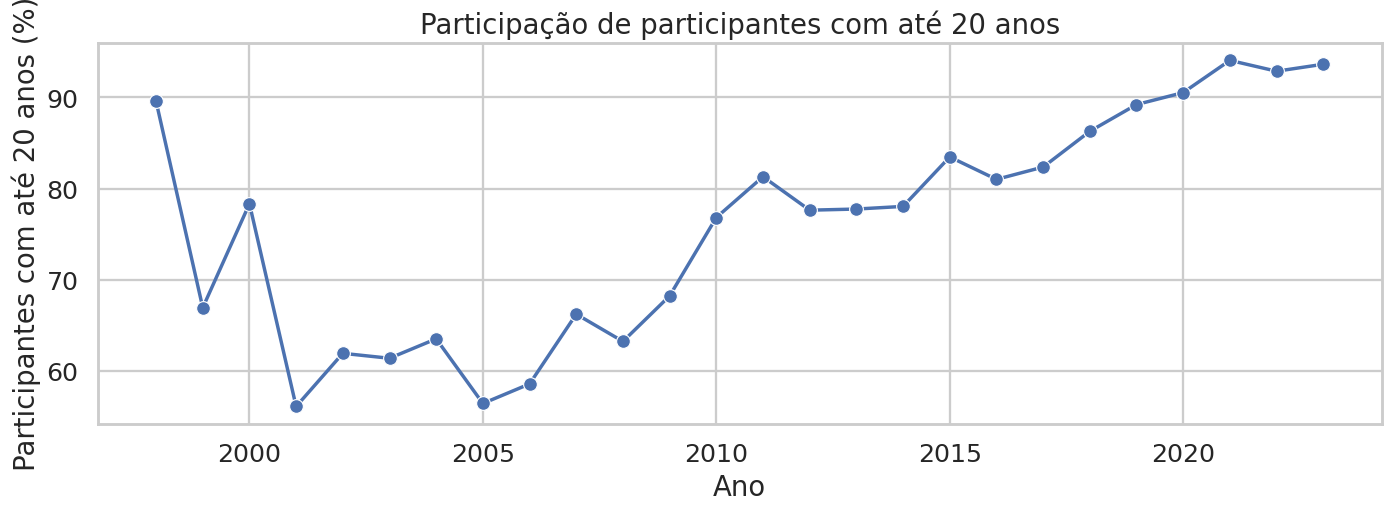

In [3]:
FAIXAS_JOVENS = ["<17", "17–20"]

jovens = distribuicao_idade.loc[
    distribuicao_idade.faixa_etaria.isin(FAIXAS_JOVENS)
].groupby("ano", as_index=False).agg(
    participantes_jovens=("participantes", "sum"),
    total_faixas_informadas=("total_referencia", "first"),
)
jovens["pct_jovens_ate_20"] = (
    jovens["participantes_jovens"]
    .div(jovens["total_faixas_informadas"].where(
        jovens["total_faixas_informadas"].gt(0)
    )) * 100
)
#display(jovens)

fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(data=jovens, x="ano", y="pct_jovens_ate_20", marker="o", ax=ax)
ax.set(title="Participação de participantes com até 20 anos",
       xlabel="Ano", ylabel="Participantes com até 20 anos (%)")
plt.tight_layout()
plt.show()



### Comentários
Considerando como jovens os participantes com até 20 anos — soma das faixas **<17** e **17–20** —, os dados mostram aumento expressivo da participação relativa desse grupo.
Em 2001, os participantes com até 20 anos representavam 56,1% dos inscritos com faixa etária informada. Em 2008, essa proporção chegou a 63,2%. A partir de 2009, o crescimento se intensificou, alcançando 78,0% em 2014 e 89,2% em 2019.Em 2023, o grupo de até 20 anos representava 93,6% dos inscritos com faixa etária informada.

houve uma mudança importante no perfil etário dos inscritos no ENEM no Pará. O exame passou a concentrar uma proporção cada vez maior de participantes com até 20 anos, enquanto a participação relativa de pessoas com mais idade diminuiu.

O resultado descreve uma mudança na composição dos inscritos. Isoladamente, não permite afirmar que aumentou o número absoluto de jovens em todas as etapas da série, nem identificar as causas dessa mudança.Em 1998, a base contém apenas 288 participantes com faixa etária informada. A proporção de 89,6% de jovens nesse ano deve ser interpretada com cautela e não é diretamente representativa da dimensão observada nos anos seguintes.



## 3. Desempenho por faixa etária

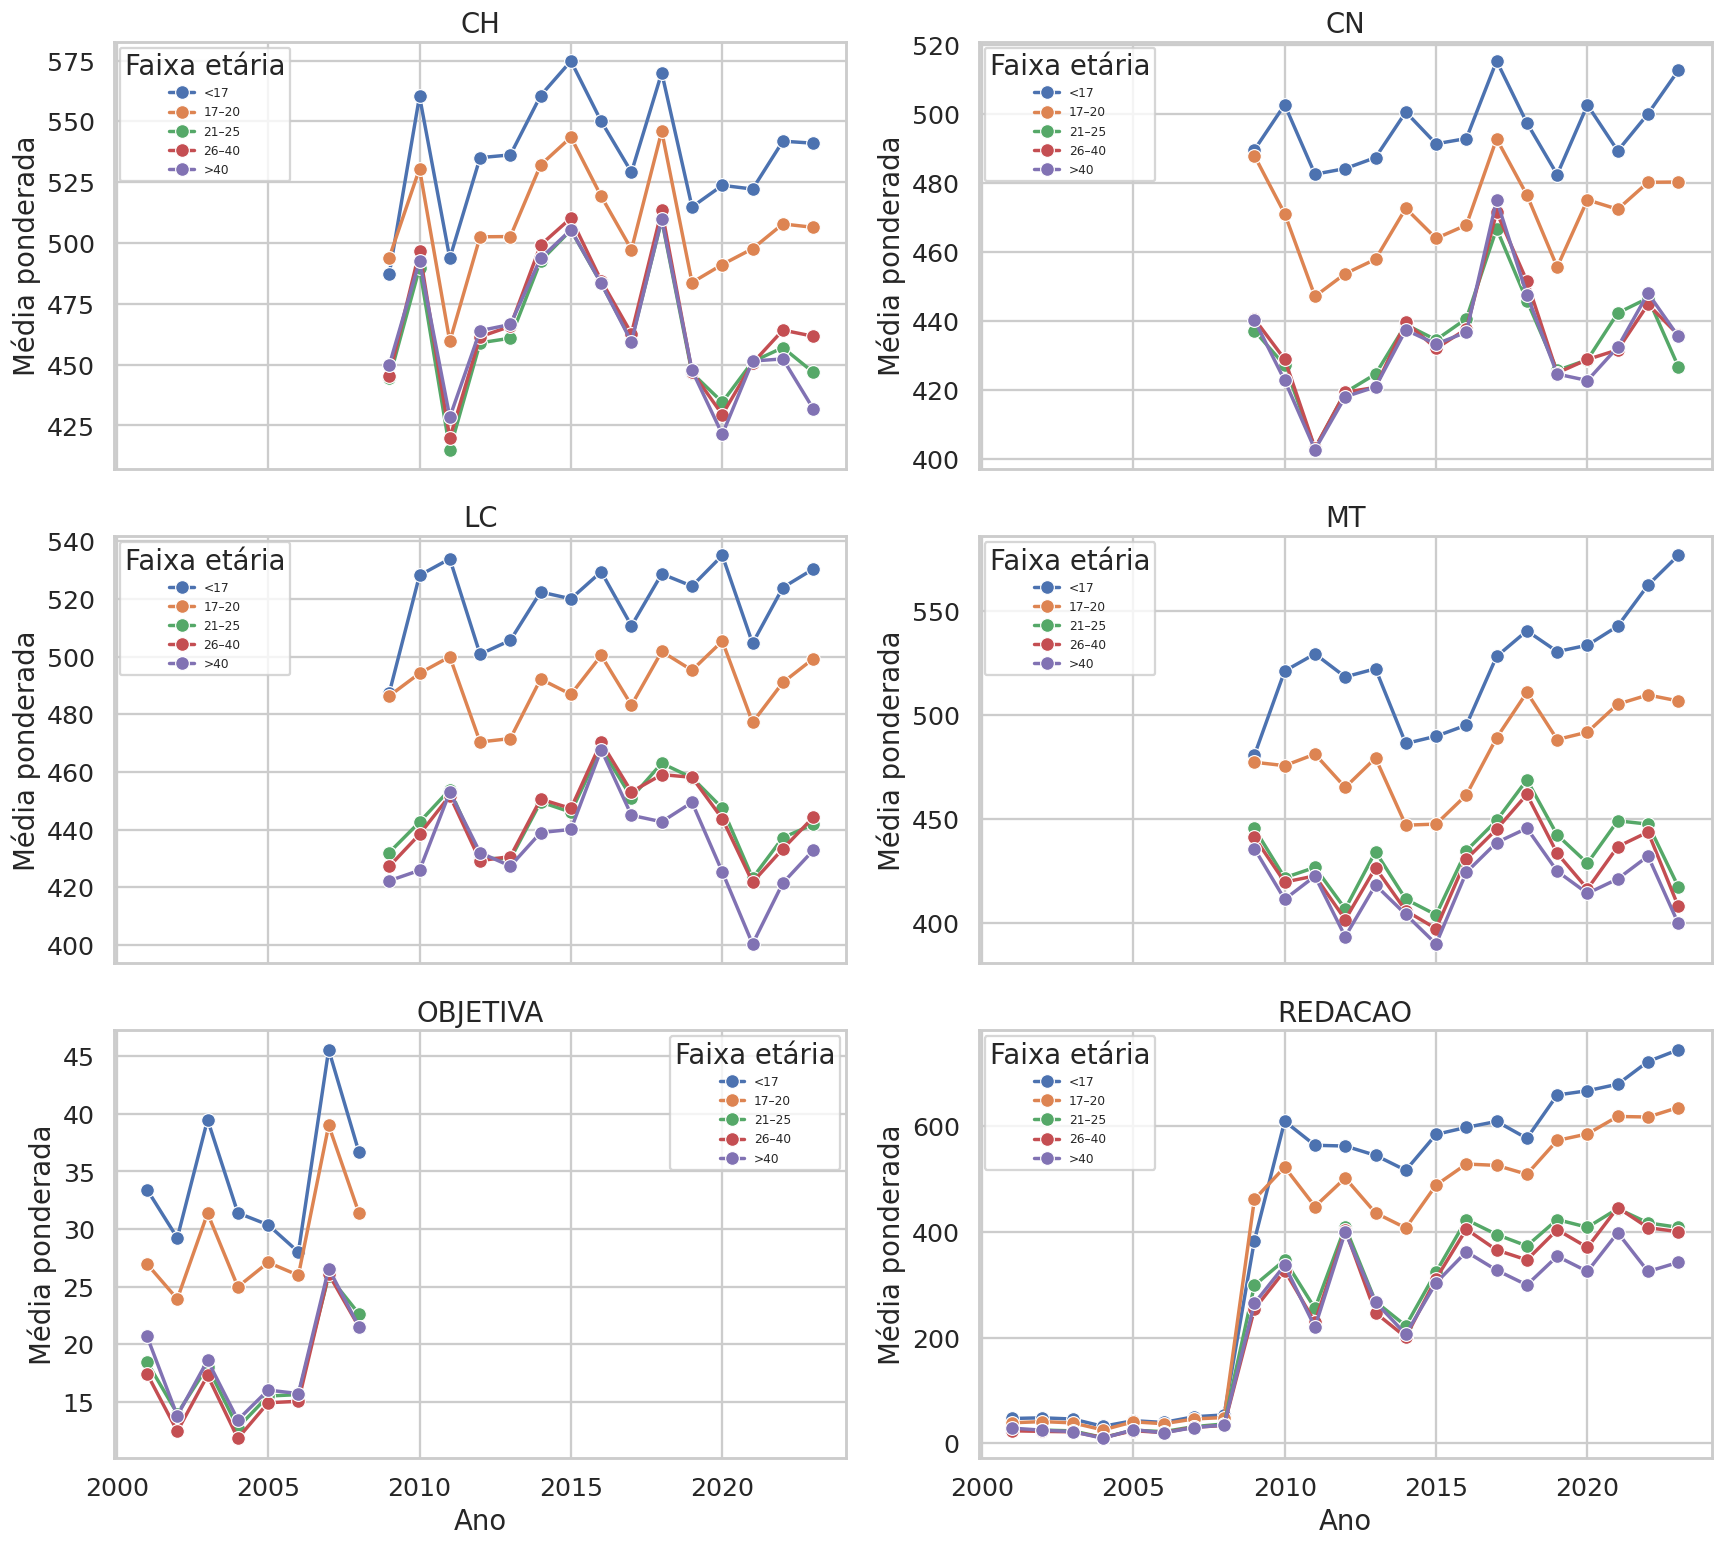

In [4]:
desempenho_faixa = eda2.agregar_desempenho_idade_dsp(desempenho_idade)
#display(desempenho_faixa)

disciplinas_i03 = sorted(desempenho_faixa.disciplina.dropna().unique())
ncols = 2
nrows = int(np.ceil(len(disciplinas_i03) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.8 * nrows), sharex=True)
axes = np.atleast_1d(axes).ravel()
for ax, disc in zip(axes, disciplinas_i03):
    tmp = desempenho_faixa.loc[desempenho_faixa.disciplina.eq(disc)]
    sns.lineplot(
        data=tmp, x="ano", y="media_ponderada",
        hue="faixa_etaria", marker="o", ax=ax
    )
    ax.set(title=disc, xlabel="Ano", ylabel="Média ponderada")
    ax.legend(title="Faixa etária", fontsize=8)
for ax in axes[len(disciplinas_i03):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()



### Comentários
Os resultados de desempenho apresentam diferenças entre as faixas etárias. De modo geral, os participantes com menos de 17 anos e aqueles entre 17 e 20 anos apresentam médias superiores às faixas mais velhas, especialmente quando comparados aos grupos de 21–25, 26–40 e >40 anos.

Essa diferença aparece nas disciplinas avaliadas a partir de 2009. Em 2023, por exemplo, a faixa <17 apresentou as maiores médias ponderadas em todas as disciplinas, seguida pela faixa 17–20.

| Disciplina | <17   | 17–20 | 21–25 | 26–40 | >40   |
| ---------- | -----:| -----:| -----:| -----:| -----:|
| CH         | 541,0 | 506,4 | 446,9 | 461,7 | 431,9 |
| CN         | 512,6 | 480,2 | 426,8 | 435,9 | 435,5 |
| LC         | 530,3 | 499,2 | 441,8 | 444,2 | 432,8 |
| MT         | 576,6 | 506,7 | 417,6 | 408,1 | 399,9 |
| Redação    | 744,6 | 635,4 | 408,7 | 400,4 | 342,4 |

*Valores de 2023; médias ponderadas por notas válidas.*

A diferença entre as faixas é particularmente expressiva em Matemática e Redação. Em 2023, a distância entre as médias de <17 e >40 foi de aproximadamente 176,7 pontos em Matemática e 402,2 pontos em Redação. As medianas municipais seguem, em linhas gerais, o mesmo padrão de vantagem das faixas mais jovens, embora existam variações entre disciplinas e grupos etários.

Os resultados indicam associação entre idade e desempenho: os grupos mais jovens tendem a apresentar médias superiores. A diferença é especialmente acentuada em Matemática e Redação. Esse padrão não deve ser interpretado como efeito causal da idade, pois a análise não controla fatores como trajetória escolar, condição socioeconômica, escolaridade anterior ou motivo de participação no exame.

**Observação:** os valores de 2001–2008 não devem ser comparados diretamente com os valores de 2009 em diante, devido à mudança de escala e estrutura do exame. A comparação entre faixas dentro de cada ano permanece mais apropriada do que a comparação direta entre os dois períodos.


## 4. Diferenças entre participantes mais jovens e mais velhos

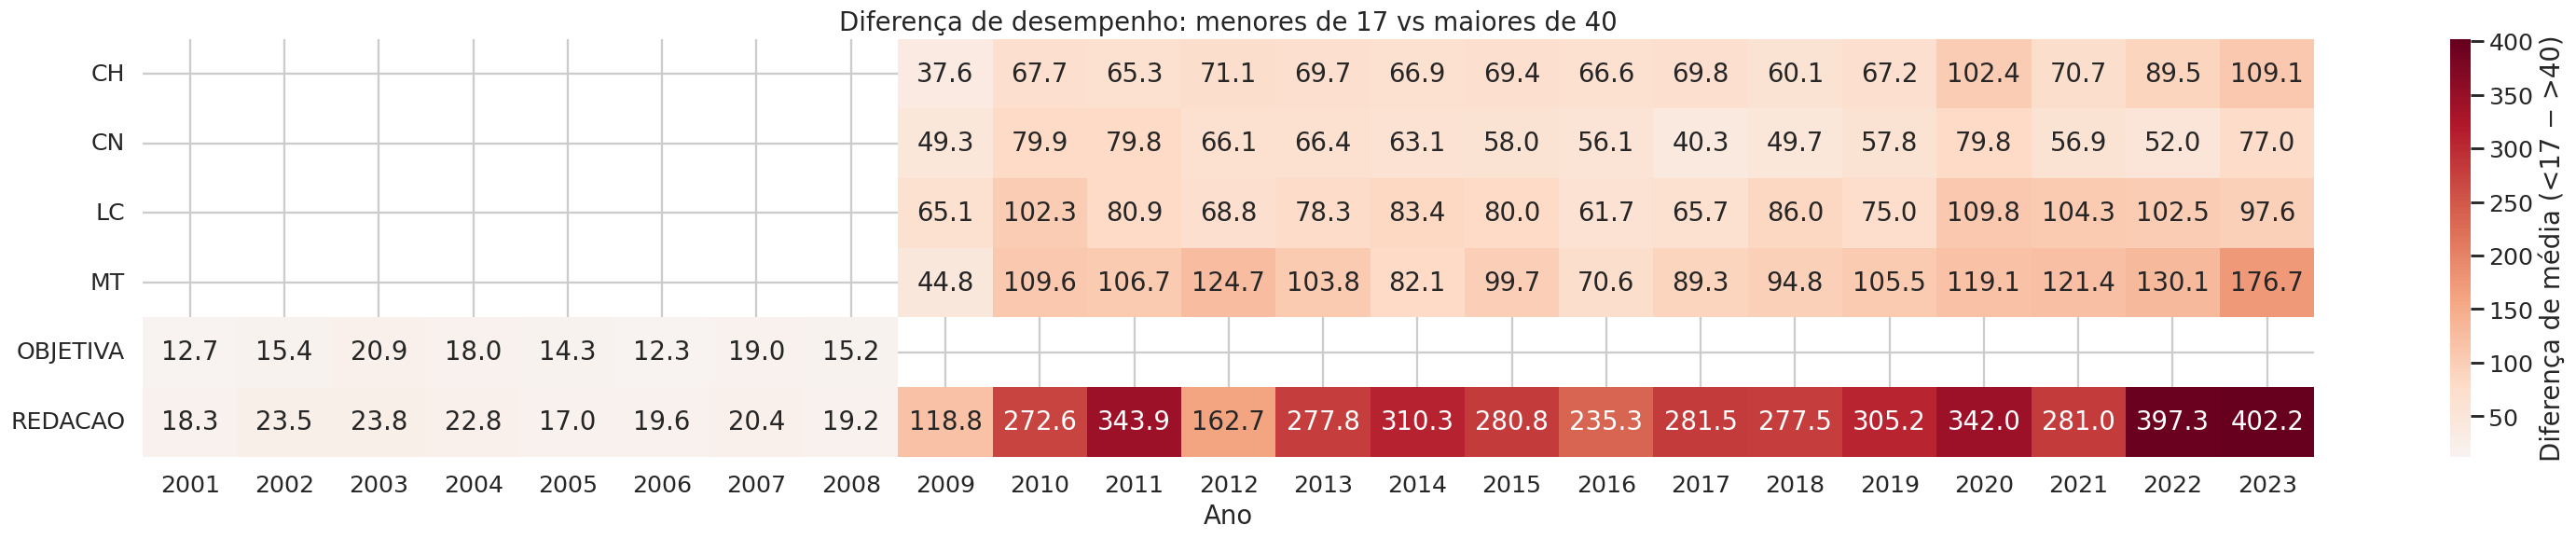

In [5]:
faixas_extremos = ["<17", ">40"]

comparacao_extremos = desempenho_faixa.loc[
    desempenho_faixa.faixa_etaria.isin(faixas_extremos)
].copy()
comparacao_extremos["grupo_etario_amplo"] = comparacao_extremos["faixa_etaria"].map({
    "<17": "MENOR_17", ">40": "MAIOR_40"
})
comparacao_extremos = comparacao_extremos.pivot_table(
    index=["ano", "disciplina"], columns="grupo_etario_amplo",
    values=["media_ponderada", "n_validos"], aggfunc="first"
)
comparacao_extremos.columns = [
    f"{metrica}_{grupo}" for metrica, grupo in comparacao_extremos.columns
]
comparacao_extremos = comparacao_extremos.reset_index()
if {"media_ponderada_MENOR_17", "media_ponderada_MAIOR_40"}.issubset(
    comparacao_extremos.columns
):
    comparacao_extremos["diferenca_menor_17_menos_maior_40"] = (
        comparacao_extremos["media_ponderada_MENOR_17"]
        - comparacao_extremos["media_ponderada_MAIOR_40"]
    )


df = comparacao_extremos.sort_values(["disciplina", "ano"]).copy()
disciplinas = df["disciplina"].unique()

n = len(disciplinas)
ncols = 3
nrows = int(np.ceil(n / ncols))

#display(comparacao_extremos)
pivot_dif = df.pivot(index="disciplina", columns="ano",
                     values="diferenca_menor_17_menos_maior_40")

plt.figure(figsize=(1.1 * pivot_dif.shape[1] + 3, 0.6 * pivot_dif.shape[0] + 2))
sns.heatmap(
    pivot_dif, annot=True, fmt=".1f", cmap="RdBu_r", center=0,
    cbar_kws={"label": "Diferença de média (<17 − >40)"}
)
plt.title("Diferença de desempenho: menores de 17 vs maiores de 40")
plt.xlabel("Ano")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Comentários
A comparação entre as faixas <17 e >40 mostra vantagem de desempenho para o grupo mais jovem em todas as disciplinas e anos analisados.Em 2001, a diferença entre as médias ponderadas dos dois grupos era de 12,7 pontos na prova objetiva e 18,3 pontos na Redação, na escala então apresentada na base.
A partir de 2009, as diferenças passam a ser expressas na escala dos resultados posteriores à reorganização do exame. Em 2023, a vantagem da faixa <17 era observada em todas as disciplinas:

| Disciplina | Média <17 | Média >40 | Diferença <17 − >40 |
| ---------- | ---------:| ---------:| -------------------:|
| CH         | 541,0     | 431,9     | 109,1               |
| CN         | 512,6     | 435,5     | 77,0                |
| LC         | 530,3     | 432,8     | 97,6                |
| MT         | 576,6     | 399,9     | 176,7               |
| Redação    | 744,6     | 342,4     | 402,2               |

A diferença é maior em Redação, seguida por Matemática. Ciências da Natureza apresenta a menor distância entre os dois grupos nesse ano.Entre 2009 e 2023, a diferença entre os grupos não apresentou uma trajetória uniforme. Em algumas disciplinas e anos, aumentou; em outros, diminuiu. Em 2023, entretanto, as distâncias são expressivas, sobretudo em Redação e Matemática.

A comparação dos extremos etários reforça que os participantes mais jovens apresentam desempenho médio superior aos participantes acima de 40 anos. A diferença varia conforme a disciplina e o ano, sendo mais acentuada em Redação e Matemática no final da série. os grupos extremos possuem tamanhos bastante diferentes. Em 2023, por exemplo, havia 473 notas válidas na faixa <17 em Redação e 117 na faixa >40, contra 27.222 na faixa 17–20. A menor dimensão dos grupos extremos recomenda cautela, especialmente na interpretação de diferenças anuais e de estatísticas municipais.


## 5. Distribuição por sexo e idade

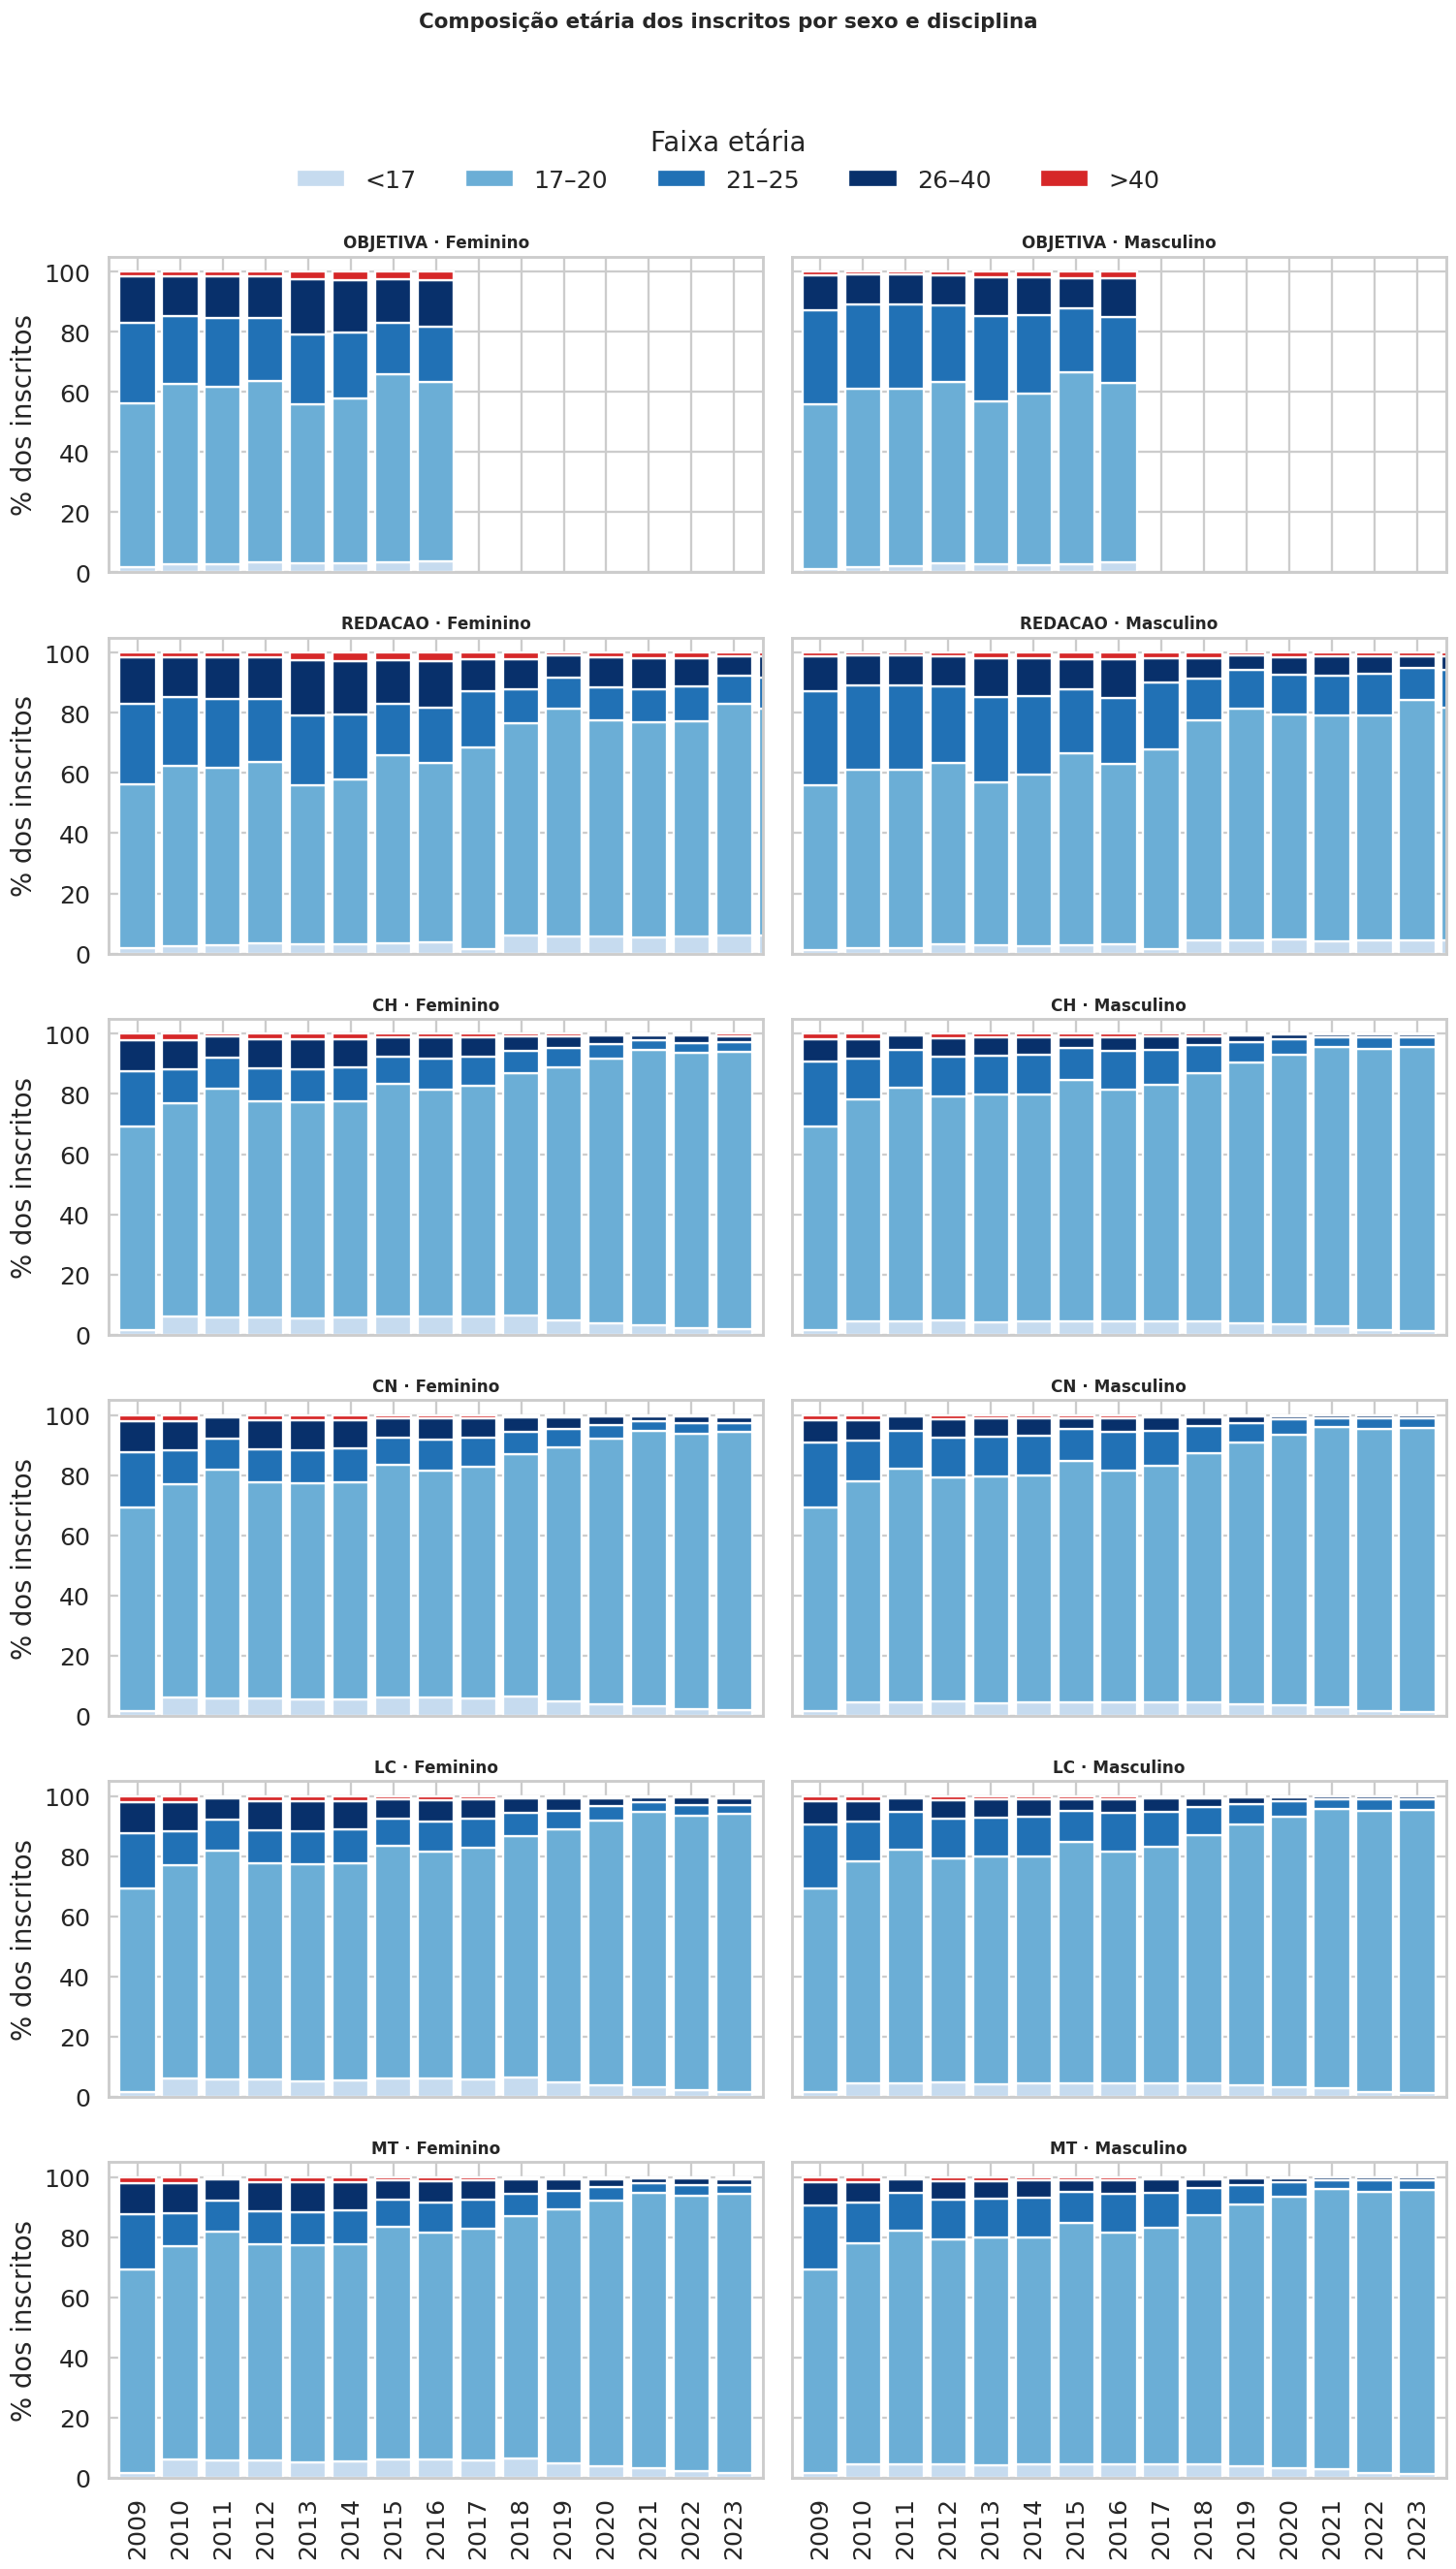

In [6]:
distribuicao_idade_sexo = eda2.calcular_distribuicao_idade_sexo_dsp(desempenho_idade)
#display(distribuicao_idade_sexo)

ordem = ["<17", "17–20", "21–25", "26–40", ">40"]
d = distribuicao_idade_sexo.copy()
d["faixa_etaria"] = pd.Categorical(d["faixa_etaria"], categories=ordem, ordered=True)

sexos = ["FEMININO", "MASCULINO"]
discs = d["disciplina"].unique()
cores = ["#c6dbef", "#6baed6", "#2171b5", "#08306b", "#d62728"]

fig, axes = plt.subplots(len(discs), 2, figsize=(14, 3.8 * len(discs)),
                         sharex=True, sharey=True, squeeze=False)

for i, disc in enumerate(discs):
    for j, sexo in enumerate(sexos):
        ax = axes[i, j]
        p = (d[(d.disciplina == disc) & (d.sexo == sexo)]
             .pivot(index="ano", columns="faixa_etaria", values="percentual")[ordem])
        p.plot(kind="bar", stacked=True, ax=ax, color=cores, width=0.85, legend=False)
        ax.set_title(f"{disc} · {sexo.title()}", fontsize=11, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("% dos inscritos" if j == 0 else "")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, frameon=False,
           bbox_to_anchor=(0.5, 1.02), title="Faixa etária")
fig.suptitle("Composição etária dos inscritos por sexo e disciplina", y=1.06,
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


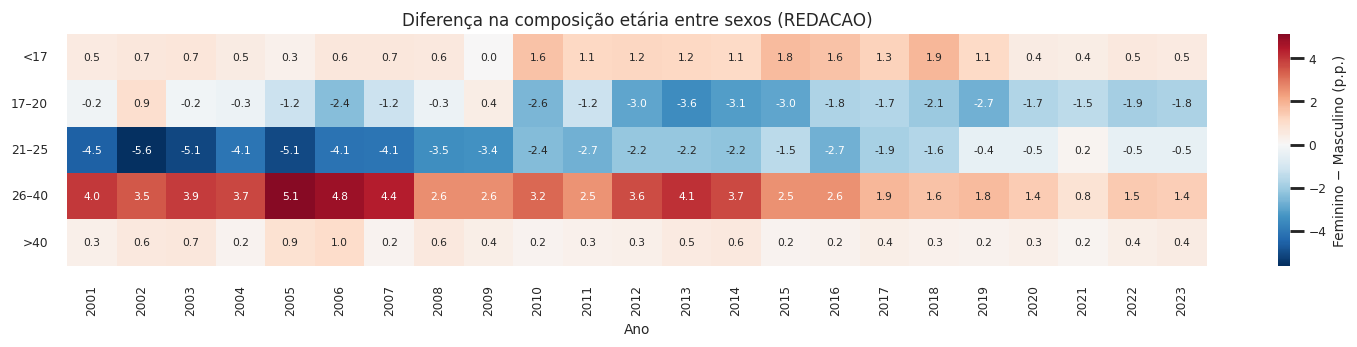

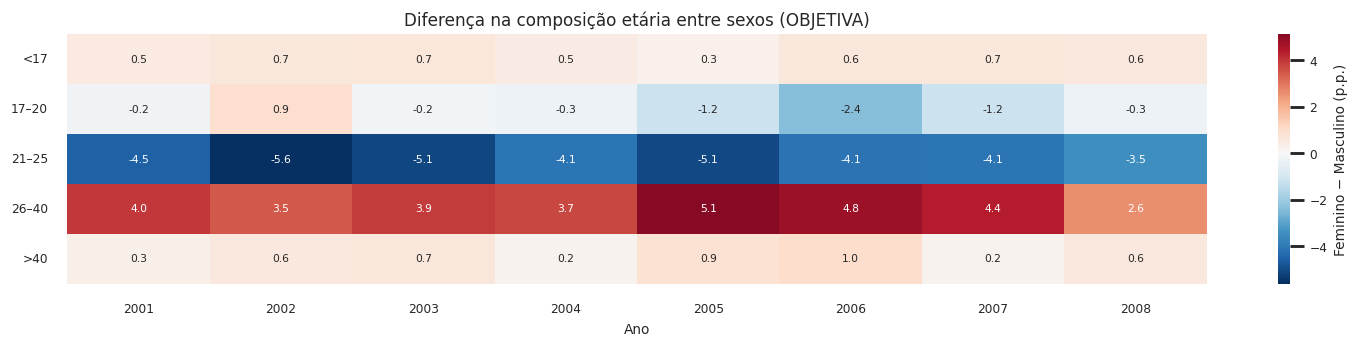

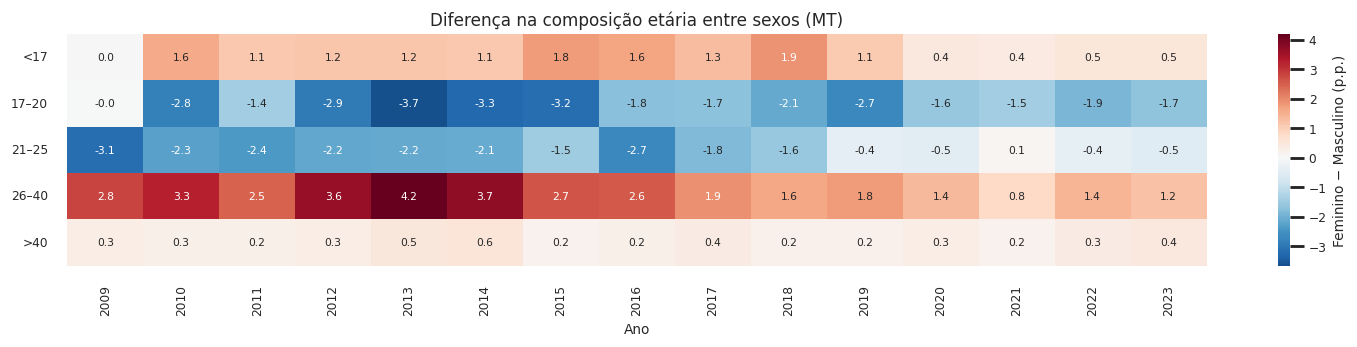

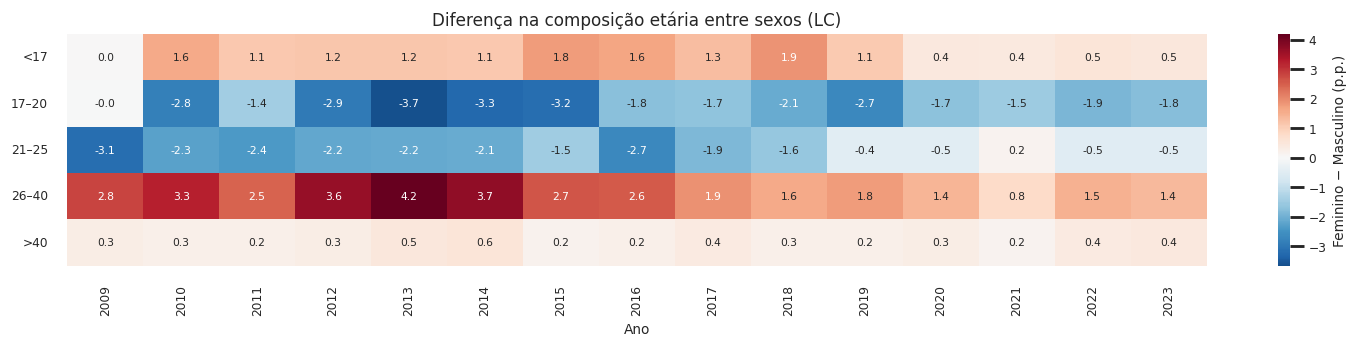

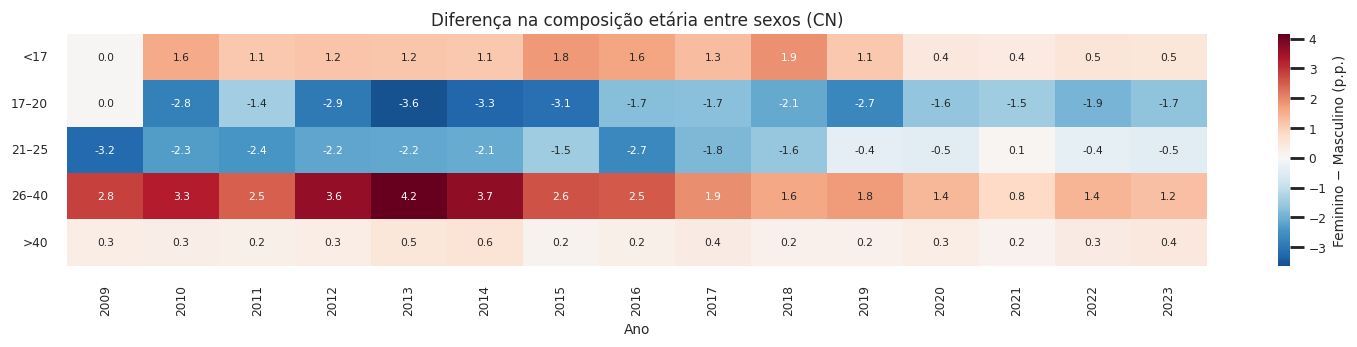

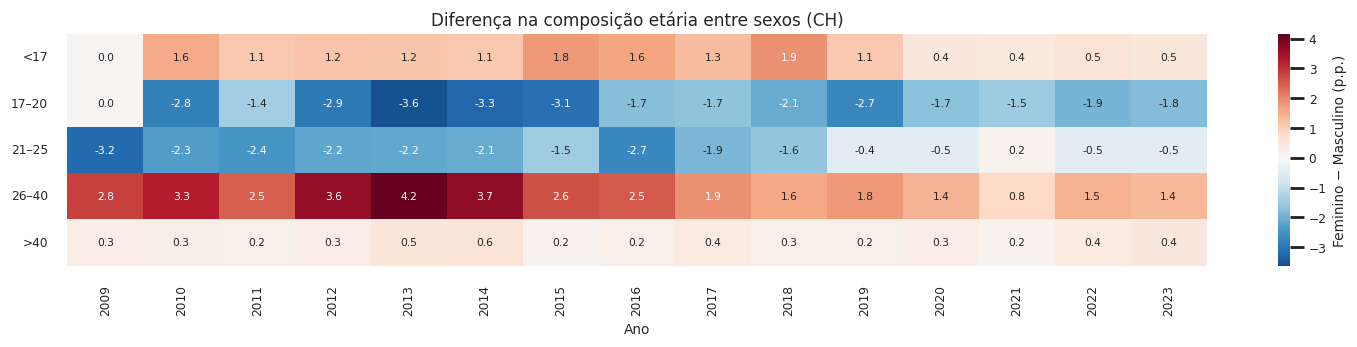

In [7]:

for J in disciplinas[::-1]:
    p = (d[d.disciplina == J].pivot_table(index=["faixa_etaria", "ano"], columns="sexo",values="percentual", observed=True))
    p["dif_pp"] = p["FEMININO"] - p["MASCULINO"]
    hm = p["dif_pp"].unstack("ano").reindex(ordem)
    
    plt.figure(figsize=(14, 3.5))
    ax = sns.heatmap(hm, annot=True, fmt=".1f", cmap="RdBu_r", center=0,
                     annot_kws={"fontsize": 7},                       # números dentro das células
                     cbar_kws={"label": "Feminino − Masculino (p.p.)"})
    
    ax.set_title(f'Diferença na composição etária entre sexos ({J})', fontsize=11)
    ax.set_xlabel("Ano", fontsize=9)
    ax.set_ylabel("")
    ax.tick_params(axis="both", labelsize=8)             # rótulos dos eixos
    ax.figure.axes[-1].tick_params(labelsize=8)          # escala da barra de cores
    ax.figure.axes[-1].yaxis.label.set_size(9)           # título da barra de cores
    plt.tight_layout()
    plt.show()

### Comentários
A distribuição etária por sexo apresenta um padrão semelhante para homens e mulheres: a faixa de 17–20 anos concentra a maior parte dos inscritos, e sua participação aumenta ao longo do período.

Em 2001, a faixa de 17–20 anos representava aproximadamente 54,5% das mulheres inscritas e 54,8% dos homens. Em 2023, esses percentuais haviam aumentado para aproximadamente 92,5% entre as mulheres e 94,3% entre os homens, considerando a disciplina CH. As demais disciplinas apresentam valores muito próximos.

Em 2023, as mulheres apresentavam participação relativa um pouco maior nas faixas de 26–40 e >40 anos, enquanto os homens apresentavam proporção ligeiramente maior na faixa de 17–20 anos.

| Sexo      | <17  | 17–20 | 21–25 | 26–40 | >40  |
| --------- | ----:| -----:| -----:| -----:| ----:|
| Feminino  | 1,7% | 92,5% | 2,9%  | 2,2%  | 0,7% |
| Masculino | 1,2% | 94,3% | 3,4%  | 0,9%  | 0,2% |


A concentração dos inscritos na faixa de 17–20 anos ocorre nos dois sexos. As diferenças entre homens e mulheres são relativamente pequenas na faixa predominante, mas as mulheres apresentam participação proporcionalmente maior nas faixas etárias mais elevadas.

O padrão se repete entre as disciplinas porque a distribuição se refere à composição dos inscritos em cada grupo, e não à quantidade de provas ou notas válidas. Pequenas diferenças entre disciplinas podem ocorrer em função da cobertura dos registros. Os percentuais são calculados separadamente dentro de cada combinação de ano, sexo e disciplina. Portanto, não devem ser somados entre disciplinas. A análise descreve a composição etária dos inscritos de cada sexo, não a diferença entre o número absoluto de homens e mulheres.



## 6. Dispersão do desempenho por faixa etária

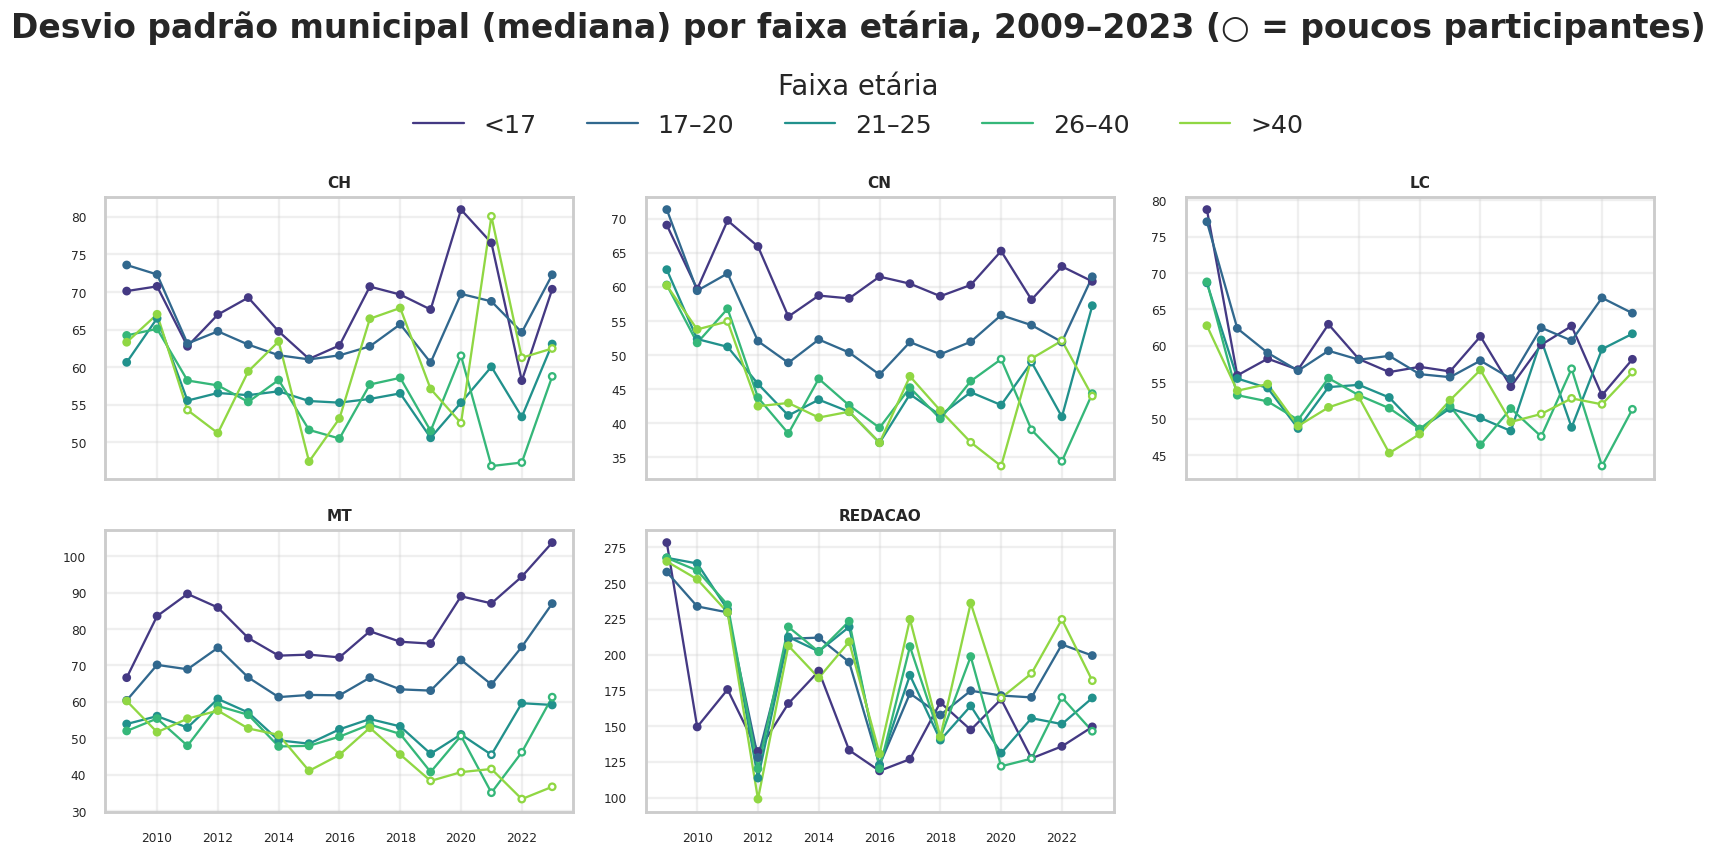

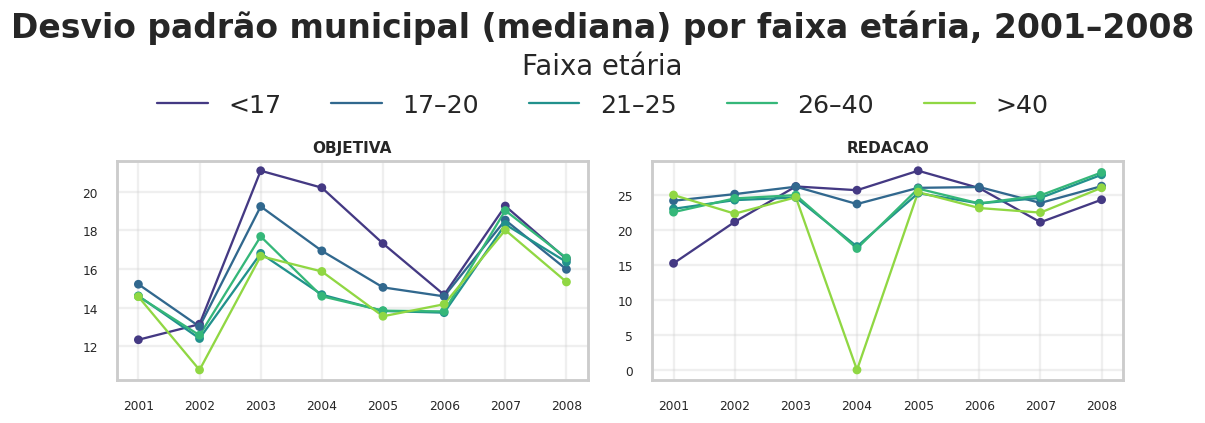

In [8]:
dispersao_idade = eda2.resumir_dispersao_idade_dsp(desempenho_idade)
#display(dispersao_idade)

ordem = ["<17", "17–20", "21–25", "26–40", ">40"]
d = dispersao_idade.copy()   # ajuste para o nome do seu DataFrame
d["faixa_etaria"] = pd.Categorical(d["faixa_etaria"], categories=ordem, ordered=True)
d["part_por_mun"] = d["n_validos"] / d["n_municipios"]
LIMIAR = 5                       # ajuste: mínimo de participantes médios por município
d["confiavel"] = d["part_por_mun"] >= LIMIAR

novo = d[d["ano"] >= 2009]       # era CH/CN/LC/MT/REDACAO
antigo = d[d["ano"] <= 2008]     # era OBJETIVA/REDACAO

def linhas_std(df, titulo, ncols=3):
    discs = df["disciplina"].unique()
    nrows = int(np.ceil(len(discs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.6 * nrows),
                             sharex=True, squeeze=False)
    pal = sns.color_palette("viridis", len(ordem))
    for ax, disc in zip(axes.flat, discs):
        for cor, faixa in zip(pal, ordem):
            s = df[(df.disciplina == disc) & (df.faixa_etaria == faixa)].sort_values("ano")
            ax.plot(s["ano"], s["std_municipal_mediana"], color=cor, lw=1.5, label=faixa)
            ax.scatter(s["ano"], s["std_municipal_mediana"], s=18, color=cor,
                       facecolors=[cor if c else "white" for c in s["confiavel"]], zorder=3)
        ax.set_title(disc, fontsize=10, fontweight="bold")
        ax.grid(alpha=0.3)
        ax.tick_params(labelsize=8)
    for ax in axes.flat[len(discs):]:
        ax.set_visible(False)
    h, l = axes.flat[0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper center", ncol=5, frameon=False, title="Faixa etária",
               bbox_to_anchor=(0.5, 1.04))
    fig.suptitle(titulo, y=1.09, fontweight="bold")
    plt.tight_layout(); plt.show()

linhas_std(novo, "Desvio padrão municipal (mediana) por faixa etária, 2009–2023 (○ = poucos participantes)")
linhas_std(antigo, "Desvio padrão municipal (mediana) por faixa etária, 2001–2008", ncols=2)

### Comentários:

A análise da dispersão utiliza a mediana municipal do desvio-padrão e a mediana municipal do intervalo interquartil (IQR). Esses indicadores descrevem a distribuição das estatísticas municipais e não a dispersão individual de todos os participantes do Pará.

Os resultados mostram que a dispersão varia conforme a disciplina e a faixa etária. Em 2023, a faixa 17–20 apresentou desvio-padrão municipal mediano de 87,0 pontos em Matemática e 199,4 pontos em Redação. Na faixa <17, os valores foram de 103,7 e 149,5 pontos, respectivamente.

| Disciplina | Faixa etária | Desvio-padrão municipal mediano | IQR municipal mediano |
| ---------- | ------------ | -------------------------------:| ---------------------:|
| CH         | <17          | 70,4                            | 11,2                  |
| CH         | 17–20        | 72,3                            | 76,7                  |
| CN         | <17          | 60,8                            | 10,1                  |
| CN         | 17–20        | 61,5                            | 62,0                  |
| LC         | <17          | 58,2                            | 6,9                   |
| LC         | 17–20        | 64,5                            | 64,3                  |
| MT         | <17          | 103,7                           | 17,4                  |
| MT         | 17–20        | 87,0                            | 88,8                  |
| Redação    | <17          | 149,5                           | 10,0                  |
| Redação    | 17–20        | 199,4                           | 180,0                 |

*Valores de 2023.*

A faixa de 17–20 anos apresenta maior cobertura territorial, com registros em 141 municípios em 2023. Nas faixas mais velhas, a quantidade de municípios com registros é menor: 101 municípios para 21–25 anos, 76 para 26–40 e 34 para >40. Essa diferença de cobertura afeta a comparabilidade das estatísticas municipais entre as faixas.

Não um padrão único de dispersão por idade. Em 2023, a faixa 17–20 apresenta dispersão municipal elevada em Redação e Matemática. A faixa <17 também apresenta desvio-padrão municipal elevado em Matemática, mas sua cobertura territorial é menor. Assim, as diferenças observadas devem ser interpretadas em conjunto com o número de municípios e de notas válidas.


## 7. Síntese dos resultados

Os resultados mostram uma mudança expressiva no perfil etário dos participantes do ENEM no Pará entre 2001 e 2023. Ao longo desse período, a participação passou a se concentrar cada vez mais nas faixas etárias mais jovens.

**Mudança no perfil etário**

A faixa de 17–20 anos passou de 54,6% dos participantes em 2001 para 92,2% em 2023. Considerando todos os participantes com até 20 anos, a proporção aumentou de 56,1% para 93,6% no mesmo período.

Em contrapartida, as faixas acima de 20 anos perderam participação relativa, especialmente a partir de 2014. Essa mudança ocorreu tanto entre homens quanto entre mulheres, embora as mulheres mantenham uma participação relativamente maior nas faixas etárias mais elevadas.

**Diferenças de desempenho entre as faixas etárias**

Em geral, os participantes mais jovens apresentaram médias superiores às dos grupos mais velhos. As maiores diferenças foram observadas na comparação entre participantes com menos de 17 anos e aqueles acima de 40 anos. Em 2023, essa distância chegou a aproximadamente 402 pontos em Redação e 177 pontos em Matemática.

Esses resultados mostram uma associação entre faixa etária e desempenho, mas não permitem afirmar que a idade, isoladamente, explique as diferenças. As faixas etárias também representam participantes com trajetórias escolares, condições socioeconômicas e motivos de participação distintos, aspectos que não foram isolados nesta análise.

**Dispersão e cobertura territorial**

As diferenças entre as faixas etárias também aparecem na variabilidade das estatísticas municipais. A dispersão dos resultados varia conforme a disciplina e o grupo etário.

A cobertura territorial, por sua vez, é desigual entre as faixas. Os grupos mais jovens estão representados em um número maior de municípios, enquanto os participantes acima de 40 anos apresentam menor cobertura e menos registros. Essa diferença limita a estabilidade das estatísticas municipais para os grupos mais velhos.

 <div style="background-color: #E2E8F0; padding: 12px; border-radius: 6px;">
    
**Síntese Final**  
Entre 2001 e 2023, o perfil etário dos participantes do ENEM no Pará tornou-se fortemente concentrado na faixa de até 20 anos. Os participantes mais jovens também apresentaram, em geral, médias superiores, com diferenças especialmente expressivas em Redação e Matemática na comparação com aqueles acima de 40 anos. A interpretação dessas diferenças deve considerar a composição etária e a desigual cobertura territorial entre os grupos. Os resultados identificam uma associação entre idade e desempenho, mas não demonstram um efeito causal isolado da idade sobre as notas
</div>

